# 4.1 · A screen of any strategy's stocks today

A **screen** ranks today's constituents by a strategy's own score and shows the numbers behind each rank, so the
reason a company scores well can be inspected and verified. It works for **any registered strategy**: every backtest
in notebooks 3.1-3.6 is registered with its whole configuration, so a run id is enough to rebuild the strategy and
score today's companies the way its backtest scored history. The screen also shows the **book the strategy would hold
if it rebalanced today**: its buffer (a name enters at one threshold and leaves only at a looser one) is replayed over
the past year, so the book is the one it would really hold, not just the top of today's ranking.

The screen never backtests: it scores today's data, adds no trial to the registry and does not reach into the
hold-out with a backtest.

It is a research tool, **not investment advice**: a high score means a company looks attractive on the strategy's
measures *relative to the other constituents today*. Factor premia are average effects across hundreds of stocks;
they say little about any single stock's next return.

**Choosing the strategy.** Set `RUN_ID` to a run id (each strategy notebook prints the ids of the runs it registers),
or `STRATEGY` to a family name for that family's latest run, or both - they are then checked against each other. The
family's recent runs are listed below the parameters. What the score is made of depends on the strategy:

| Strategy kind | Score | Parts shown |
|---|---|---|
| A factor mix (3.1-3.4) | the weighted mean of the factor z-scores | each factor's z-score: +1 = one standard deviation better than the cross-sectional mean |
| S&P 500 GARP (3.5) | the quality & value z-score, among the best growth scores only (the rest are not candidates) | `growth`, `quality_value` |
| Barings QGARP (3.6) | QGARP as a percentile: 100 = the best | its composites: percentile ranks (1 = best) and z-scores |

**Other columns:**

| Column | Definition |
|---|---|
| `rank` | 1 = the highest score |
| `weight` | the weight the strategy would hold if it rebalanced today (negative: short; 0: not held) |
| `return_12_1` | the total return over the past 12 months excluding the most recent month |
| `volatility` | annualised standard deviation of daily returns |
| `P/E` | price / earnings per share: the price paid per unit of annual earnings (lower = cheaper) |
| `P/B` | price / book value per share: the price paid per unit of shareholders' equity on the balance sheet |
| `EV/EBIT` | enterprise value (market cap + debt - cash) per unit of operating profit; unlike P/E, independent of capital structure |
| `RoE` | return on equity: net income / shareholders' equity |
| `Debt/Equity` | total debt / shareholders' equity: financial leverage |

In [1]:
# Which registered run to screen. A run id names one strategy exactly; STRATEGY alone takes that family's latest
# run; given both, they must agree. ON is the day to screen (None: today).
RUN_ID = 74  # notebook 3.2's second long-only version
STRATEGY = "multi_factor_lo"
ON = None

In [2]:
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research.cache import ResearchCache
from equity_research.research.classification import listing_sectors
from equity_research.research.runs import load_run, registered_runs, snapshot
from equity_research.research.screen import strategy_screen

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()

run = load_run(engine, RUN_ID, family=STRATEGY)
print("Recent runs of this family:")
display(registered_runs(engine, run.family).head(8).style.format(precision=3, na_rep="-").hide(axis="index"))

today = snapshot(cache, run.config, on=ON)
table = strategy_screen(cache, today)
PARTS = list(today.parts.columns)
held = table[table["weight"] != 0]
print(
    f"{run.label}: registered {run.finished_at:%d %B %Y}, backtested {run.config.start} to {run.config.end}, "
    f"CAGR {run.metrics.get('cagr', float('nan')):.1%}, Sharpe {run.metrics.get('sharpe', float('nan')):.2f}"
)
print(
    f"{len(table):,} {run.config.universe} companies ranked on {today.day:%A %d %B %Y}; "
    f"it would hold {(held['weight'] > 0).sum()} long and {(held['weight'] < 0).sum()} short"
)

Recent runs of this family:


family,finished_at,run_id,universe,start,end,cagr,sharpe,information_ratio,deflated_sharpe
multi_factor_lo,2026-11-14 18:35:57,83,SP1500,2010-01-01,2024-12-31,0.140,0.891,-0.048,0.962
multi_factor_lo,2026-11-14 18:33:59,82,SP1500,2010-01-01,2024-12-31,0.136,0.871,-0.137,0.960
multi_factor_lo,2026-11-14 18:32:02,81,SP1500,2006-01-01,2024-12-31,0.099,0.628,-0.163,0.885
multi_factor_lo,2026-11-14 18:29:55,80,SP1500,2010-01-01,2024-12-31,0.129,0.846,-0.276,0.962
multi_factor_lo,2026-11-14 18:28:00,79,SP1500,2010-01-01,2024-12-31,0.143,0.902,0.023,0.980
multi_factor_lo,2026-11-14 18:26:07,78,SP1500,2010-01-01,2024-12-31,0.137,0.880,-0.110,0.980
multi_factor_lo,2026-11-14 18:22:19,77,SP1500,2010-01-01,2024-12-31,0.135,0.869,-0.165,0.978
multi_factor_lo,2026-11-14 18:21:19,76,SP1500,2006-01-01,2024-12-31,0.107,0.663,-0.008,0.953


left out 887 facts of 2 companies in ['GBP']


run 74 · multi_factor_lo: value, quality, momentum, low_vol, issuance: registered 14 November 2026, backtested 2010-01-01 to 2024-12-31, CAGR 13.7%, Sharpe 0.88
1,501 SP1500 companies ranked on Thursday 12 November 2026; it would hold 528 long and 0 short


## The top 25

In [3]:
SHOW = [
    "rank",
    "ticker",
    "name",
    "segment",
    "score",
    "weight",
    *PARTS,
    "return_12_1",
    "volatility",
    "P/E",
    "P/B",
    "EV/EBIT",
    "RoE",
    "Debt/Equity",
]
SHOW = [c for c in SHOW if c in table.columns]
FORMAT = {
    "score": "{:.2f}",
    "weight": "{:.1%}",
    **{part: "{:+.2f}" for part in PARTS},
    "return_12_1": "{:.0%}",
    "volatility": "{:.0%}",
    "P/E": "{:.1f}",
    "P/B": "{:.1f}",
    "EV/EBIT": "{:.1f}",
    "RoE": "{:.0%}",
    "Debt/Equity": "{:.2f}",
}
display(table[SHOW].head(25).style.format(FORMAT, na_rep="-").hide(axis="index"))

rank,ticker,name,segment,score,weight,value,quality,momentum,low_vol,issuance,return_12_1,volatility,P/E,P/B,EV/EBIT,RoE,Debt/Equity
1,CXW,"CoreCivic, Inc.",small,1.33,0.0%,+1.85,+1.18,+1.66,-0.31,+2.25,89%,42%,1.9,1.2,1.4,63%,0.27
2,ADIG,ADI Global Distribution Inc.,small,1.23,0.0%,+2.22,+0.25,-,-,-,-,70%,-,0.6,-,-,0.48
3,PBI,Pitney Bowes Inc.,small,1.14,0.0%,+0.67,-,+1.48,+0.28,+2.15,77%,33%,11.6,-2.6,14.9,-22%,-2.26
4,DINO,HF Sinclair Corporation,mid,1.10,0.1%,+1.61,+0.78,+2.12,-0.29,+1.30,132%,41%,4.9,1.5,3.6,30%,0.24
5,COKE,"Coca-Cola Consolidated, Inc.",mid,1.09,0.0%,-,+1.11,+0.77,-0.00,+2.49,31%,37%,-,-,-,-172%,-7.40
6,VLO,Valero Energy Corp,large,1.08,0.4%,+1.05,+0.62,+2.29,-0.16,+1.58,154%,39%,7.8,3.6,5.8,46%,0.39
7,RNR,RenaissanceRe Holdings Ltd.,mid,1.08,0.1%,+1.17,+0.50,+0.67,+1.12,+1.93,27%,23%,9.2,1.3,5.2,14%,0.21
8,EG,"Everest Group, Ltd.",large,1.07,0.1%,+1.23,+0.55,+0.34,+1.35,+1.89,16%,22%,8.3,1.1,7.6,13%,0.17
9,TRV,"The Travelers Companies, Inc.",large,1.05,0.3%,+0.71,+0.75,+0.78,+1.51,+1.51,32%,21%,9.8,2.8,8.4,29%,0.34
10,MPC,Marathon Petroleum Corporation,large,1.02,0.5%,+0.98,+0.33,+2.17,-0.04,+1.65,142%,38%,7.7,4.8,6.0,63%,1.42


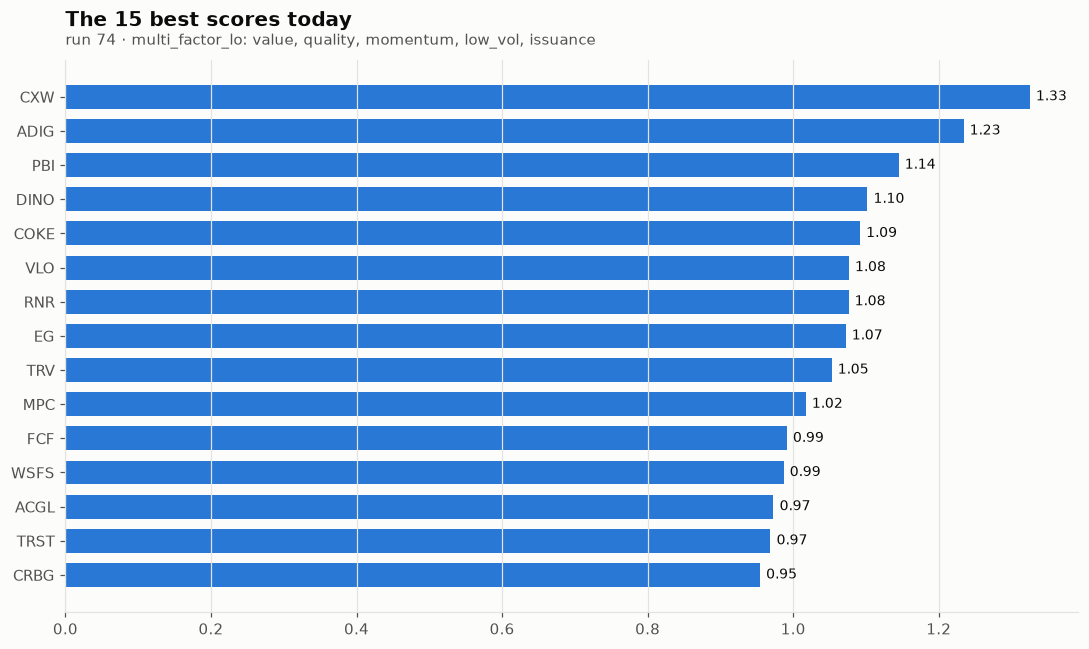

In [4]:
top = table.head(15).set_index("ticker")["score"]
fig = charts.ranked_bars(top, "The 15 best scores today", subtitle=run.label)

## Score decomposition of the top-ranked stock

Each bar is one part of the strategy's score for the highest-ranked company (z-scores: 0 = the average company;
QGARP's percentile ranks: 1 = the best). A mix shows which parts carry its rank.

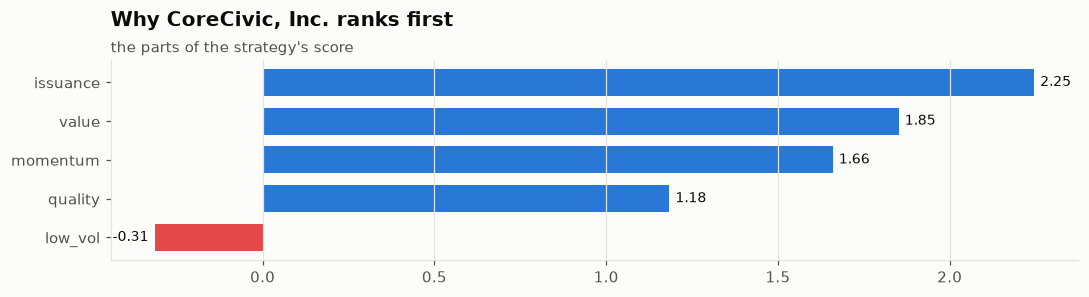

In [5]:
first = table.iloc[0]
fig = charts.ranked_bars(
    first[PARTS].astype(float).dropna(),
    f"Why {first['name']} ranks first",
    subtitle="the parts of the strategy's score",
)

## The book it would hold today

The names and weights the strategy would hold if it rebalanced today, with its buffer replayed over the past year (a
name already held stays until it falls past the exit threshold). If the long book is concentrated in one sector, the
strategy is partly a sector bet rather than a stock-selection one - worth knowing before acting on it.

rank,ticker,name,segment,score,weight,value,quality,momentum,low_vol,issuance,return_12_1,volatility,P/E,P/B,EV/EBIT,RoE,Debt/Equity
325,AAPL,Apple Inc.,large,0.34,20.7%,-1.43,+1.33,+0.59,+0.93,+0.25,25%,25%,39.1,46.1,32.8,118%,0.71
354,MU,"Micron Technology, Inc.",large,0.31,3.7%,+0.07,+1.38,+2.75,-1.99,-0.66,279%,84%,10.8,6.6,8.9,61%,0.04
349,JPM,JPMorgan Chase & Co.,large,0.31,3.7%,+0.17,-0.25,+0.01,+1.17,+0.46,6%,23%,13.8,2.4,13.1,18%,1.43
122,XOM,Exxonmobil Holdings Corp,large,0.60,2.7%,+0.32,+0.20,+1.10,+0.73,+0.67,48%,27%,16.7,2.6,13.5,15%,0.13
353,JNJ,Johnson & Johnson,large,0.31,2.7%,-1.02,+0.54,+0.76,+1.46,-0.19,31%,21%,41.9,8.3,37.5,20%,0.55
402,MA,Mastercard Incorporated,large,0.28,2.3%,-1.45,+1.08,+0.08,+1.10,+0.59,8%,23%,34.1,85.6,27.8,251%,3.54
250,ABBV,AbbVie Inc.,large,0.41,2.1%,-1.01,+1.81,+0.63,+0.89,-0.25,26%,25%,50.4,-113.8,27.9,-226%,-17.65
437,COST,Costco Wholesale Corp,large,0.26,1.9%,-0.82,+0.71,+0.05,+1.57,-0.22,7%,20%,52.2,13.5,39.9,26%,0.17
280,KO,Coca-Cola Co,large,0.38,1.7%,-0.94,+0.50,+0.69,+1.88,-0.24,28%,19%,28.7,11.2,29.2,39%,1.11
108,CVX,Chevron Corporation,large,0.63,1.7%,+0.47,+0.27,+1.01,+0.97,+0.45,42%,25%,15.5,2.2,10.9,14%,0.17


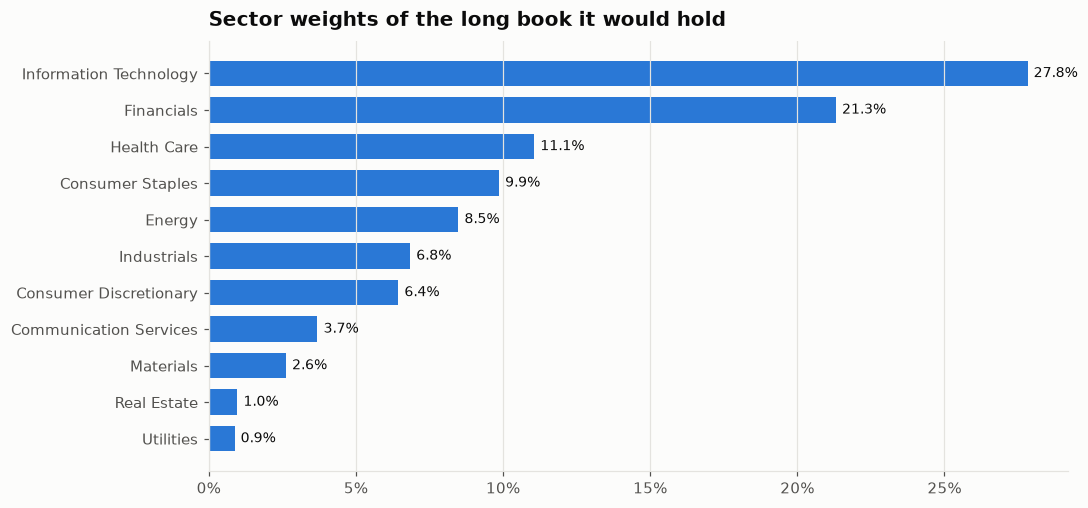

In [6]:
book = held.sort_values("weight", ascending=False)
display(book[SHOW].style.format(FORMAT, na_rep="-").hide(axis="index"))
longs = book["weight"].clip(lower=0.0)
by_sector = longs.groupby(listing_sectors(cache, longs.index).reindex(longs.index).to_numpy()).sum()
fig = charts.ranked_bars(by_sector[by_sector > 0], "Sector weights of the long book it would hold", percent=True)

## The bottom 10

The lowest scores: the names a long-short version of the strategy would short.

In [7]:
display(table[SHOW].tail(10).style.format(FORMAT, na_rep="-").hide(axis="index"))

rank,ticker,name,segment,score,weight,value,quality,momentum,low_vol,issuance,return_12_1,volatility,P/E,P/B,EV/EBIT,RoE,Debt/Equity
1492,RCUS,"Arcus Biosciences, Inc.",small,-1.28,0.0%,-1.84,-1.55,+0.19,-1.27,-1.91,11%,62%,-5.3,6.7,-3.9,-127%,0.28
1493,HIMS,"Hims & Hers Health, Inc.",mid,-1.30,0.0%,-1.05,-0.62,-1.34,-2.31,-1.18,-30%,93%,-25.5,13.7,-17.9,-54%,-
1494,KTOS,"Kratos Defense & Security Solutions, Inc.",mid,-1.34,0.0%,-0.98,-0.51,-2.03,-1.51,-1.68,-49%,70%,313.1,2.0,856.8,1%,0.00
1495,KRMN,Karman Holdings Inc,small,-1.36,0.0%,-1.46,-0.55,-2.42,-2.05,-0.33,-57%,87%,117.4,13.4,61.5,11%,1.94
1496,AVAV,"AeroVironment, Inc.",mid,-1.43,0.0%,-0.45,-1.00,-2.93,-1.78,-1.00,-63%,78%,-31.2,1.4,-25.6,-5%,0.17
1497,SEDG,"SolarEdge Technologies, Inc.",small,-1.49,0.0%,-0.65,-1.67,-1.41,-2.42,-1.30,-32%,94%,-7.2,3.9,-9.0,-54%,-
1498,LQDA,Liquidia Corporation,small,-1.57,0.0%,-1.47,-3.31,+0.53,-2.34,-1.27,22%,93%,-52.8,-195.6,-47.3,370%,-
1499,MARA,"MARA Holdings, Inc.",small,-1.59,0.0%,-0.81,-2.06,-1.86,-2.09,-1.11,-44%,88%,-1.0,1.3,-1.8,-125%,1.28
1500,LEU,Centrus Energy Corp.,small,-1.62,0.0%,-0.65,-1.25,-2.39,-2.07,-1.74,-56%,87%,30.4,2.1,-220.5,7%,1.07
1501,FMC,FMC Corp,small,-1.68,0.0%,-0.68,-2.22,-1.77,-1.72,-1.99,-42%,76%,-0.2,-45.3,-1.6,21936%,-215.35


## Custom filters

A screen is customised by adding conditions. Two examples: large caps only, and stocks that are cheap on earnings
while also in a positive price trend.

In [8]:
large = table[table["segment"] == "large"]
display(large[SHOW].head(10).style.format(FORMAT, na_rep="-").hide(axis="index"))

cheap_and_rising = table[(table["P/E"] > 0) & (table["P/E"] < 15) & (table["return_12_1"] > 0)]
print(f"{len(cheap_and_rising)} companies have a P/E under 15 and a positive 12-1 month return")
display(cheap_and_rising[SHOW].head(10).style.format(FORMAT, na_rep="-").hide(axis="index"))

rank,ticker,name,segment,score,weight,value,quality,momentum,low_vol,issuance,return_12_1,volatility,P/E,P/B,EV/EBIT,RoE,Debt/Equity
6,VLO,Valero Energy Corp,large,1.08,0.4%,+1.05,+0.62,+2.29,-0.16,+1.58,154%,39%,7.8,3.6,5.8,46%,0.39
8,EG,"Everest Group, Ltd.",large,1.07,0.1%,+1.23,+0.55,+0.34,+1.35,+1.89,16%,22%,8.3,1.1,7.6,13%,0.17
9,TRV,"The Travelers Companies, Inc.",large,1.05,0.3%,+0.71,+0.75,+0.78,+1.51,+1.51,32%,21%,9.8,2.8,8.4,29%,0.34
10,MPC,Marathon Petroleum Corporation,large,1.02,0.5%,+0.98,+0.33,+2.17,-0.04,+1.65,142%,38%,7.7,4.8,6.0,63%,1.42
13,ACGL,Arch Capital Group Ltd.,large,0.97,0.1%,+1.01,+0.51,+0.06,+1.43,+1.86,8%,21%,8.1,1.5,6.5,19%,-
17,HON,Honeywell International Inc.,large,0.95,0.3%,+0.46,+0.77,-0.12,+0.80,+2.83,4%,26%,10.2,3.2,12.3,31%,0.63
18,FDX,FedEx Corp,large,0.95,0.3%,+0.77,+0.14,+0.83,+0.63,+2.36,35%,28%,8.8,2.2,14.2,25%,0.56
29,V,Visa Inc.,large,0.87,0.0%,-,+1.34,+0.33,+1.20,+0.63,15%,23%,-,-,-,65%,0.61
31,AMP,Ameriprise Financial Inc,large,0.86,0.2%,+0.39,+1.88,+0.03,+0.77,+1.24,7%,27%,10.8,8.8,6.6,81%,-
32,VYLR,Vylor Inc.,large,0.86,0.2%,-0.06,+1.79,-,-,-,-,44%,-,2.8,-,-,0.01


228 companies have a P/E under 15 and a positive 12-1 month return


rank,ticker,name,segment,score,weight,value,quality,momentum,low_vol,issuance,return_12_1,volatility,P/E,P/B,EV/EBIT,RoE,Debt/Equity
1,CXW,"CoreCivic, Inc.",small,1.33,0.0%,+1.85,+1.18,+1.66,-0.31,+2.25,89%,42%,1.9,1.2,1.4,63%,0.27
3,PBI,Pitney Bowes Inc.,small,1.14,0.0%,+0.67,-,+1.48,+0.28,+2.15,77%,33%,11.6,-2.6,14.9,-22%,-2.26
4,DINO,HF Sinclair Corporation,mid,1.10,0.1%,+1.61,+0.78,+2.12,-0.29,+1.30,132%,41%,4.9,1.5,3.6,30%,0.24
6,VLO,Valero Energy Corp,large,1.08,0.4%,+1.05,+0.62,+2.29,-0.16,+1.58,154%,39%,7.8,3.6,5.8,46%,0.39
7,RNR,RenaissanceRe Holdings Ltd.,mid,1.08,0.1%,+1.17,+0.50,+0.67,+1.12,+1.93,27%,23%,9.2,1.3,5.2,14%,0.21
8,EG,"Everest Group, Ltd.",large,1.07,0.1%,+1.23,+0.55,+0.34,+1.35,+1.89,16%,22%,8.3,1.1,7.6,13%,0.17
9,TRV,"The Travelers Companies, Inc.",large,1.05,0.3%,+0.71,+0.75,+0.78,+1.51,+1.51,32%,21%,9.8,2.8,8.4,29%,0.34
10,MPC,Marathon Petroleum Corporation,large,1.02,0.5%,+0.98,+0.33,+2.17,-0.04,+1.65,142%,38%,7.7,4.8,6.0,63%,1.42
11,FCF,First Commonwealth Financial Corp,small,0.99,0.0%,+0.82,+0.40,+0.59,+1.81,+1.34,24%,19%,11.8,1.4,5.5,12%,0.19
12,WSFS,WSFS Financial Corporation,small,0.99,0.0%,+0.70,+0.68,+0.84,+1.34,+1.37,36%,22%,12.2,1.6,5.4,13%,0.08


## Limits of a screen

* **Verify the inputs.** A P/E of 3 may be a genuine bargain or the result of a one-off gain inflating last year's
  earnings. Check the company's latest filing.
* **Scores are relative.** "Cheap" means cheap relative to today's cross-section, not cheap in any absolute sense; in
  an expensive market the cheapest stocks can still be expensive.
* **Today's data and code.** The strategy is rebuilt from its registered settings but scored with today's data and
  code; its registered backtest used those of its day.
* **Past performance is not a forecast.** The strategy's own notebook shows how the same scores performed
  historically, including the bad years.